## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Alejandro Peña Martinez" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa necesita organizar las tareas de mantenimiento que tiene pendientes. Como algunas son más urgentes que otra no seria conveniente atenderlas en el orden que llegan para eso utilizaremos una cola de prioridad con un Max-Heap para que la tarea con mayor importancia o prioridad quede en la raíz.


## 2) Requerimientos Funcionales y No Funcionales**[2 pts]**

 **Requerimientos Funcionales:**


1.   Organizar las seis tareas mediante un Max-Heap.
2.   Extraer las dos tareas con mayor prioridad
3.   Calcular las distancias entre todas las parejas de dispositivos.
4.   Obtener y tambien mostrar las cinco conexiones del MST y su costo total.

 **Requerimientos no Funcionales:**.

1.   Utilizar Python en un unico Notebook.
2.   Mostrar las distancias con dos decimales.
3.   Presentar graficas claras.
4.   Implementar Kruskal sin funciones que calculen directamente el MST.




## 3) Historias de usuario **[2 pts]**

*  **H.U1:** Como tecnico, quiero organizarlas tareas por orden de prioridad para saber cual atender primero.

      **C.A:** Mostrar el arreglo inicial utlizando Max-Heap y su arbol.

*  **H.U2:** Como tecnico, quiero retirar las tareas mas urgentes para atenderlas en orden.

     **C.A:** Extraer T02 y despues T04, mostrando el Heap despues de cada extraccion que se haga.

*  **H.U3:** Como personal de mantenimiento, quiero agregar una emergencia para atenderla antes que las demas.


    **C.A:** Insertar T07 con prioridad 12 y comprobar que quede en la raiz.

*  **H.U4:** Como encargado de la red, quiero conocer la distancia de los dispositivos para comparar conexiones disponibles.

    **C.A:** Mostrar las seis posiciones y calculas las distancias mediante formula eucidiana.






## 4) Diagramas de flujo **[5 pts]**


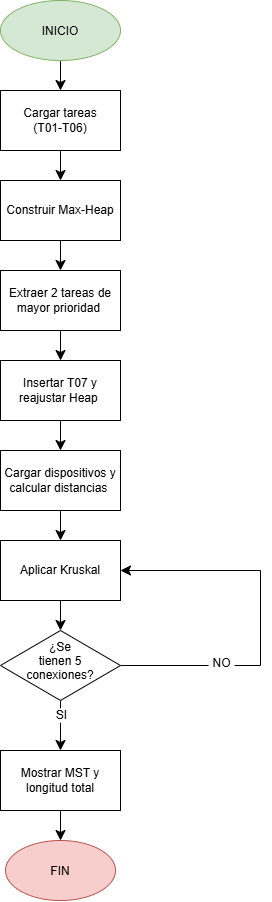


### 5) Análisis de complejidad **[15 pts]**

MAX-HEAPIFY, EXTRACT-MAX e insercion recorren como máximo la altura del heap, el mejor caso O(1), peor caso O(log n). BUILD-MAX-HEAP tiene costo de O(n) porque la mayoria de los nodos estan cerca de las hojas.

Para v dispositivos se generan e=v(v-1)/2 aristas. Calcular la distancia cuesta O(v^2). Kruskal ordena las aristas en O(e log e) y utiliza conjuntos y utiliza conjuntos disjuntos con comprension de caminos y union por tamaño. Su costo total esta dominado por O(e log e). El espacio es O(v+e).

**MEJOR CASO**

   **T(n)=1**

**PEOR CASO**

   **T(n)=1 + [log2n]**

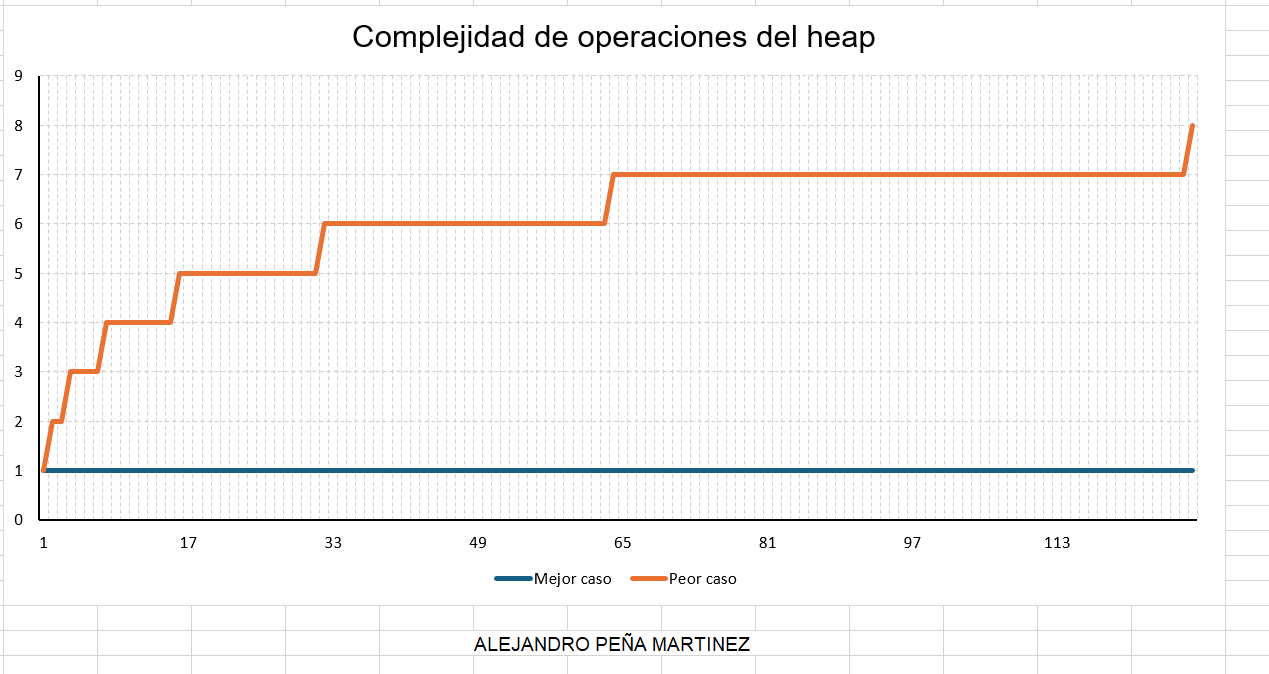




## 6) Código funcional **[15 pts]**

### Punto 1. Cola de prioridad

Arreglo inicial:
[('T01', 6), ('T02', 10), ('T03', 4), ('T04', 8), ('T05', 3), ('T06', 7)]
Max-Heap resultante:
[('T02', 10), ('T04', 8), ('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


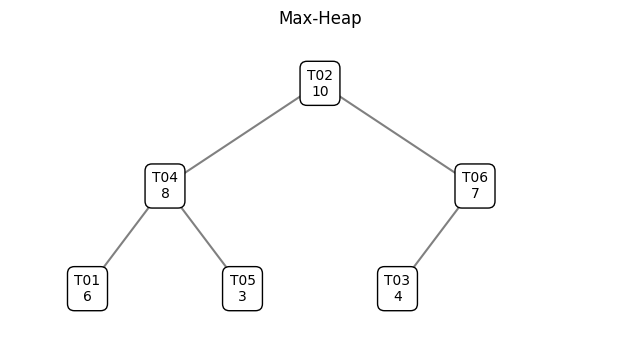

In [ ]:
import matplotlib.pyplot as plt
from math import sqrt, log2, floor

tareas = [
    ('T01', 'Configurar servidor', 6),
    ('T02', 'Reparar sensor', 10),
    ('T03', 'Actualizar software', 4),
    ('T04', 'Revisar cámara', 8),
    ('T05', 'Generar respaldo', 3),
    ('T06', 'Configurar alarma', 7)
]

def max_heapify(heap, i):
    mayor = i
    izq = 2*i + 1
    der = 2*i + 2
    if izq < len(heap) and heap[izq][2] > heap[mayor][2]:
        mayor = izq
    if der < len(heap) and heap[der][2] > heap[mayor][2]:
        mayor = der
    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor)

def build_max_heap(heap):
    for i in range(len(heap)//2 - 1, -1, -1):
        max_heapify(heap, i)

def mostrar_heap(heap):
    arreglo = []
    for tarea in heap:
        arreglo.append((tarea[0], tarea[2]))
    print(arreglo)

def dibujar_heap(heap):
    fig, ax = plt.subplots(figsize=(8,4))
    posiciones = {}
    for i, tarea in enumerate(heap):
        nivel = floor(log2(i+1))
        lugar = i - (2**nivel - 1)
        x = (lugar + 0.5)/2**nivel
        y = -nivel
        posiciones[i] = (x,y)
        if i > 0:
            px, py = posiciones[(i-1)//2]
            ax.plot([px,x],[py,y], color='gray', zorder=1)
        ax.text(x,y,f'{tarea[0]}\n{tarea[2]}', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black'), zorder=2)
    ax.set_xlim(0,1)
    ax.set_ylim(-max(1,floor(log2(max(1,len(heap)))))-0.5,0.5)
    ax.set_title('Max-Heap')
    ax.axis('off')
    plt.show()

heap = tareas.copy()
print('Arreglo inicial:')
mostrar_heap(heap)
build_max_heap(heap)
print('Max-Heap resultante:')
mostrar_heap(heap)
dibujar_heap(heap)

### Punto 2. Procesar tareas

Tarea procesada: ('T02', 'Reparar sensor', 10)
Heap resultante:
[('T04', 8), ('T01', 6), ('T06', 7), ('T03', 4), ('T05', 3)]
Tarea procesada: ('T04', 'Revisar cámara', 8)
Heap resultante:
[('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]
Heap después de insertar T07:
[('T07', 12), ('T06', 7), ('T05', 3), ('T03', 4), ('T01', 6)]


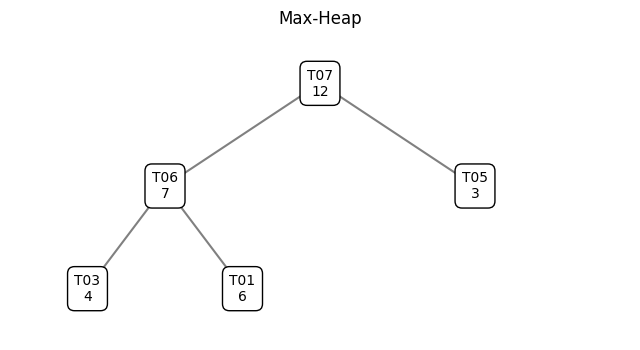

In [ ]:
def extract_max(heap):
    if not heap:
        return None
    mayor = heap[0]
    ultimo = heap.pop()
    if heap:
        heap[0] = ultimo
        max_heapify(heap, 0)
    return mayor

def insertar(heap, tarea):
    heap.append(tarea)
    i = len(heap)-1
    while i > 0:
        padre = (i-1)//2
        if heap[padre][2] >= heap[i][2]:
            break
        heap[padre], heap[i] = heap[i], heap[padre]
        i = padre

heap = tareas.copy()
build_max_heap(heap)
procesadas = []
for i in range(2):
    tarea = extract_max(heap)
    procesadas.append(tarea)
    print('Tarea procesada:', tarea)
    print('Heap resultante:')
    mostrar_heap(heap)

insertar(heap, ('T07', 'Falla en sistema contra incendios', 12))
print('Heap después de insertar T07:')
mostrar_heap(heap)
dibujar_heap(heap)

### Punto 3. Dispositivos a conectar

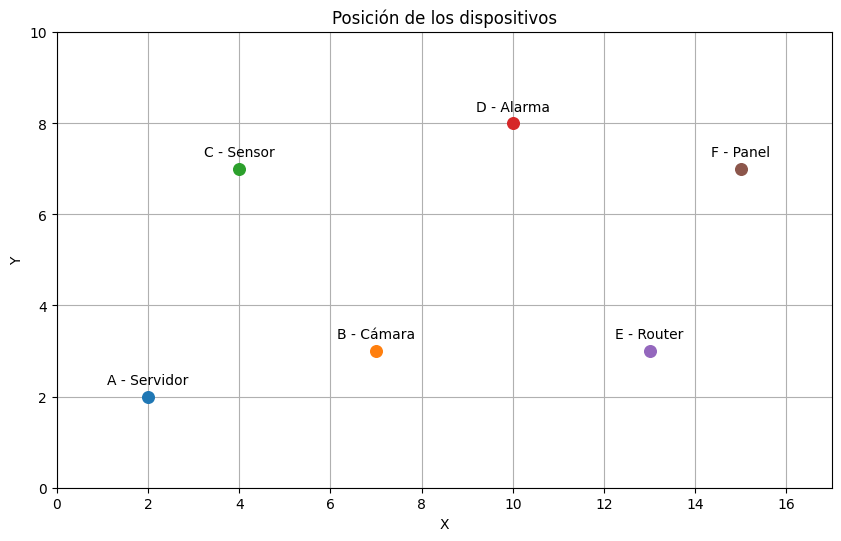

A - B : 5.10
A - C : 5.39
A - D : 10.00
A - E : 11.05
A - F : 13.93
B - C : 5.00
B - D : 5.83
B - E : 6.00
B - F : 8.94
C - D : 6.08
C - E : 9.85
C - F : 11.00
D - E : 5.83
D - F : 5.10
E - F : 4.47


In [ ]:
dispositivos = {
    'A': ('Servidor', 2, 2),
    'B': ('Cámara', 7, 3),
    'C': ('Sensor', 4, 7),
    'D': ('Alarma', 10, 8),
    'E': ('Router', 13, 3),
    'F': ('Panel', 15, 7)
}

def dibujar_dispositivos(ax):
    for id, (nombre,x,y) in dispositivos.items():
        ax.scatter(x,y,s=70,zorder=3)
        ax.annotate(f'{id} - {nombre}', (x,y), xytext=(0,9), textcoords='offset points', ha='center')
    ax.set_xlim(0,17)
    ax.set_ylim(0,10)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_aspect('equal')
    ax.grid()

fig, ax = plt.subplots(figsize=(10,6))
dibujar_dispositivos(ax)
ax.set_title('Posición de los dispositivos')
plt.show()

aristas = []
ids = list(dispositivos)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a = ids[i]
        b = ids[j]
        x1 = dispositivos[a][1]
        y1 = dispositivos[a][2]
        x2 = dispositivos[b][1]
        y2 = dispositivos[b][2]
        peso = sqrt((x2-x1)**2 + (y2-y1)**2)
        aristas.append((peso, a, b))
        print(f'{a} - {b} : {peso:.2f}')

### Punto 4. Árbol de expansión mínima

In [ ]:
def find(padre, v):
    if padre[v] != v:
        padre[v] = find(padre, padre[v])
    return padre[v]

def union(padre, tamano, a, b):
    a = find(padre, a)
    b = find(padre, b)
    if a == b:
        return False
    if tamano[a] < tamano[b]:
        a, b = b, a
    padre[b] = a
    tamano[a] += tamano[b]
    return True

def kruskal(vertices, aristas):
    padre = {}
    tamano = {}
    for v in vertices:
        padre[v] = v
        tamano[v] = 1
    mst = []
    for peso, a, b in sorted(aristas):
        if union(padre, tamano, a, b):
            mst.append((peso, a, b))
            if len(mst) == len(vertices) - 1:
                break
    return mst

mst = kruskal(dispositivos, aristas)
total = 0
for peso, a, b in mst:
    total += peso
    print(f'{a} - {b} : {peso:.2f}')
print(f'Longitud total de cable: {total:.2f}')

E - F : 4.47
B - C : 5.00
A - B : 5.10
D - F : 5.10
B - D : 5.83
Longitud total de cable: 25.50


### Punto 5. Visualización final

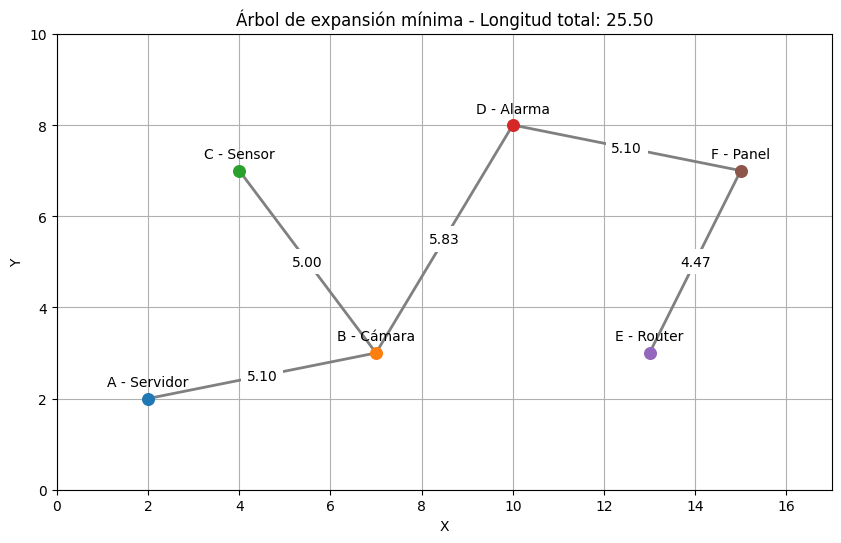

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))
for peso,a,b in mst:
    _,x1,y1 = dispositivos[a]
    _,x2,y2 = dispositivos[b]
    ax.plot([x1,x2],[y1,y2],color='gray',linewidth=2)
    ax.text((x1+x2)/2,(y1+y2)/2,f'{peso:.2f}',ha='center',va='center',bbox=dict(facecolor='white',edgecolor='none'))
dibujar_dispositivos(ax)
ax.set_title(f'Árbol de expansión mínima - Longitud total: {total:.2f}')
plt.show()

## 7) Tests aplicados **[15 pts]**

In [ ]:
def es_max_heap(heap):
    for i in range(1, len(heap)):
        padre = (i - 1) // 2
        if heap[padre][2] < heap[i][2]:
            return False
    return True

assert procesadas[0][0] == 'T02'
assert procesadas[1][0] == 'T04'
assert heap[0][0] == 'T07'
assert es_max_heap(heap)
assert extract_max([]) is None
assert len(aristas) == 15
assert len(mst) == 5
padre = {}
tamano = {}
for v in dispositivos:
    padre[v] = v
    tamano[v] = 1
for peso, a, b in mst:
    assert union(padre, tamano, a, b)
for v in dispositivos:
    assert find(padre, v) == find(padre, 'A')
assert round(total, 2) == 25.50
assert kruskal(['A'], []) == []
print('Todas las pruebas pasaron.')

Todas las pruebas pasaron.
